BEST HYPERPARAMETERS:
{'classifier__C': 1, 'tfidf__max_features': 7000, 'tfidf__ngram_range': (1, 2)}

Best Cross-Validation F1 Score:
0.8523

PERFORMANCE COMPARISON:
              Model  Accuracy  Macro F1 Score
Original Linear SVM    0.9378          0.8975
   Tuned Linear SVM    0.9422          0.9057

TUNED MODEL CLASSIFICATION REPORT:
              precision    recall  f1-score   support

          ai       0.95      0.77      0.85        47
   classical       0.94      0.99      0.96       178

    accuracy                           0.94       225
   macro avg       0.94      0.88      0.91       225
weighted avg       0.94      0.94      0.94       225



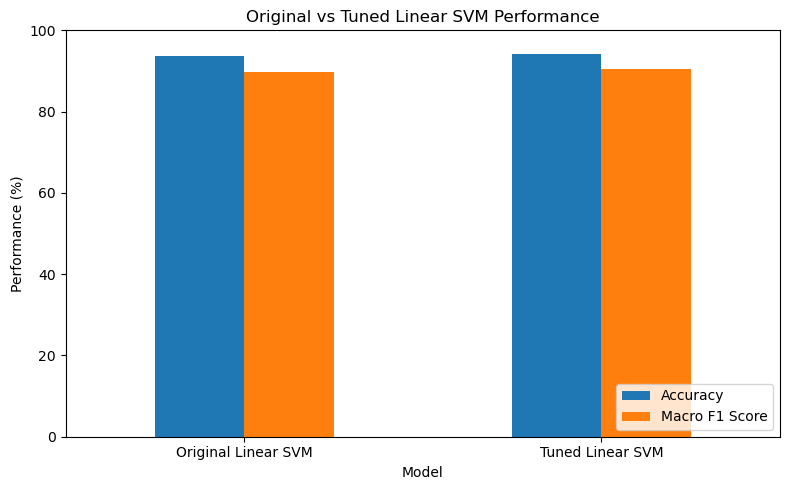

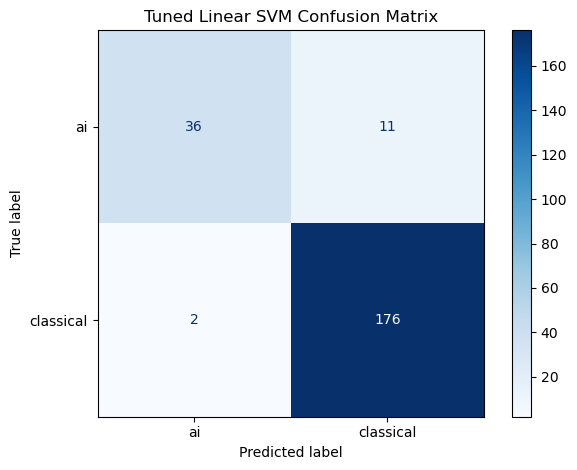


Selected Model: Tuned Linear SVM
Model saved successfully!

Question 2.2 Completed Successfully!


In [6]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import joblib

# 1. Use the same training and testing data from 2.1
# X_train, X_test, y_train, y_test

# 2. Build the original Linear SVM model
original_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ('classifier', LinearSVC(
        class_weight='balanced',
        random_state=42
    ))
])

# Train the original model
original_model.fit(X_train, y_train)

# Predict using original model
original_pred = original_model.predict(X_test)

original_accuracy = accuracy_score(y_test, original_pred)
original_f1 = f1_score(
    y_test, original_pred,
    average='macro'
)

# 3. Define the hyperparameter search grid
param_grid = {
    'tfidf__max_features': [3000, 5000, 7000],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'classifier__C': [0.1, 1, 10]
}

# 4. Apply 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=original_model,
    param_grid=param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

# 5. Train and optimise the model
grid_search.fit(X_train, y_train)

# 6. Display best parameters
print("BEST HYPERPARAMETERS:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(grid_search.best_score_, 4))

# 7. Evaluate the optimised model
tuned_model = grid_search.best_estimator_

tuned_pred = tuned_model.predict(X_test)

tuned_accuracy = accuracy_score(y_test, tuned_pred)
tuned_f1 = f1_score(
    y_test, tuned_pred,
    average='macro'
)

# 8. Compare original and tuned model performance
comparison = pd.DataFrame({
    'Model': ['Original Linear SVM', 'Tuned Linear SVM'],
    'Accuracy': [original_accuracy, tuned_accuracy],
    'Macro F1 Score': [original_f1, tuned_f1]
})

print("\nPERFORMANCE COMPARISON:")
print(comparison.round(4).to_string(index=False))

# 9. Display optimised classification report
print("\nTUNED MODEL CLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    tuned_pred,
    zero_division=0
))

# 10. Visualise performance comparison
comparison_plot = comparison.set_index('Model') * 100

comparison_plot.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Original vs Tuned Linear SVM Performance')
plt.ylabel('Performance (%)')
plt.xlabel('Model')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 11. Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tuned_pred,
    cmap='Blues'
)

plt.title('Tuned Linear SVM Confusion Matrix')
plt.tight_layout()
plt.show()

# 12. Save the model with the higher test macro F1
if tuned_f1 > original_f1:
    final_model = tuned_model
    final_name = 'Tuned Linear SVM'
else:
    final_model = original_model
    final_name = 'Original Linear SVM'

joblib.dump(final_model, 'researchly_best_model.joblib')

print("\nSelected Model:", final_name)
print("Model saved successfully!")
print("\nQuestion 2.2 Completed Successfully!")
